## First small models

### Imports

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import laspy
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils import resample, class_weight
from scipy.spatial import cKDTree
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from imblearn.over_sampling import SMOTE
import seaborn as sns
from collections import defaultdict
import matplotlib.pyplot as plt

### Load data from multiple files

In [111]:
# === Automatically find all .laz files ===
folder_path = "C:/Users/flori/Desktop/pa-1_data/training"  
file_paths = glob.glob(os.path.join(folder_path, "*.laz"))
print(f"Found {len(file_paths)} LAZ files.")

# === Prepare containers ===
all_features = []
all_labels = []

# === Create label map based on all files together ===
# (First pass to get all unique labels)
all_labels_raw = []
for path in file_paths:
    las_temp = laspy.read(path)
    all_labels_raw.extend(np.unique(las_temp.classification))

unique_labels = np.unique(all_labels_raw)
# Remove class 7 
unique_labels = unique_labels[unique_labels != 7]

label_map = {label: idx for idx, label in enumerate(unique_labels)}
print("Label Map:", label_map)

# === load and process all files ===
for path in file_paths:
    las = laspy.read(path)


    # Extract features
    ground_height = np.min(las.z)
    X = np.vstack((
        las.x,
        las.y,
        las.z,
        las.intensity,
        las.return_number,
        las.number_of_returns,
        las.z - ground_height,
        las.scan_angle
    )).T.astype(np.float32)

    y_raw = np.array(las.classification)

    # Remove points with class 7 (error class) 
    mask_valid = (y_raw != 7) 
    X = X[mask_valid]
    y_raw = y_raw[mask_valid]

    # map labels
    y_mapped = np.array([label_map[label] for label in y_raw])


    all_features.append(X)
    all_labels.append(y_mapped)

# === Stack everything together ===
X_combined = np.vstack(all_features)
y_combined = np.hstack(all_labels)

print("\n=== Combined dataset ===")
print("X shape:", X_combined.shape)
print("y shape:", y_combined.shape)

# Print class distribution
class_counts = pd.Series(y_combined).value_counts().sort_index()
print("\nClass distribution of combined files:\n")
print(class_counts)

Found 28 LAZ files.
Label Map: {np.uint8(1): 0, np.uint8(2): 1, np.uint8(3): 2, np.uint8(4): 3, np.uint8(5): 4, np.uint8(6): 5, np.uint8(15): 6, np.uint8(17): 7}

=== Combined dataset ===
X shape: (235874742, 8)
y shape: (235874742,)

Class distribution of combined files:

0      3591197
1    136887078
2      3701565
3     10499531
4     30076103
5     50596991
6       125747
7       396530
Name: count, dtype: int64


### Preprocessing

In [ ]:
# === Standardize features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_combined)

# === Skip SMOTE for now ===
X_resampled, y_resampled = X_scaled, y_combined

# === Center each point cloud ===
N_POINTS = 1024
X_centered = X_resampled.copy()

for i in range(0, len(X_centered), N_POINTS):
    chunk = X_centered[i:i+N_POINTS]
    centroid = np.mean(chunk[:, :3], axis=0)
    X_centered[i:i+N_POINTS, :3] -= centroid

In [113]:
# Parameters
target_samples_per_class = 125_000  # adjusted based on class with least samples

# Group points by class
class_indices = defaultdict(list)
for idx, label in enumerate(y_resampled):
    class_indices[label].append(idx)

# Balanced indices: keep all rare, limit common
balanced_indices = []
for label, indices in class_indices.items():
    if len(indices) <= target_samples_per_class:
        balanced_indices.extend(indices)
    else:
        balanced_indices.extend(np.random.choice(indices, target_samples_per_class, replace=False))

# Shuffle indices to mix
np.random.shuffle(balanced_indices)

# Get balanced X and y
X_balanced = X_resampled[balanced_indices]
y_balanced = y_resampled[balanced_indices]

# Trim to fit full point clouds
num_samples = len(X_balanced) // N_POINTS
X_balanced = X_balanced[:num_samples * N_POINTS]
y_balanced = y_balanced[:num_samples * N_POINTS]

# Reshape into (num_clouds, 1024, features)
X_pointcloud = X_balanced.reshape(num_samples, N_POINTS, -1)
y_pointcloud = y_balanced.reshape(num_samples, N_POINTS)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_pointcloud, y_pointcloud, test_size=0.2, random_state=42)


#### Data augmentation for better generalization

In [114]:
def random_rotate_pointcloud(batch_pointcloud):
    batch_size = tf.shape(batch_pointcloud)[0]  # <--- use tf.shape
    angles = tf.random.uniform((batch_size,), minval=0, maxval=2 * np.pi)  # np.pi is fine here because it's a float

    cos_vals = tf.cos(angles)
    sin_vals = tf.sin(angles)

    zeros = tf.zeros_like(cos_vals)
    ones = tf.ones_like(cos_vals)

    rotation_matrices = tf.stack([
        tf.stack([cos_vals, -sin_vals, zeros], axis=1),
        tf.stack([sin_vals, cos_vals, zeros], axis=1),
        tf.stack([zeros, zeros, ones], axis=1)
    ], axis=1)  # shape: (batch_size, 3, 3)

    points_xyz = batch_pointcloud[:, :, :3]
    points_rest = batch_pointcloud[:, :, 3:]  # all other features (e.g., intensity, etc.)

    rotated_xyz = tf.matmul(points_xyz, rotation_matrices)
    rotated_pointcloud = tf.concat([rotated_xyz, points_rest], axis=-1)

    return rotated_pointcloud

def jitter_pointcloud(batch_pointcloud, sigma=0.01, clip=0.05):
    jitter = tf.clip_by_value(
        sigma * tf.random.normal(tf.shape(batch_pointcloud)),
        -clip,
        clip
    )
    return batch_pointcloud + jitter

def augment_fn(X, y):
    X = random_rotate_pointcloud(X)
    X = jitter_pointcloud(X)
    return X, y

In [115]:
# --- Create datasets ---
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train))
test_dataset = tf.data.Dataset.from_tensor_slices((X_test, y_test))

# --- Augment only training data ---
train_dataset = train_dataset.shuffle(buffer_size=1024)
train_dataset = train_dataset.batch(64)
# train_dataset = train_dataset.map(augment_fn, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

# --- Validation dataset: no augmentation ---
test_dataset = test_dataset.batch(64)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)


### PointNet

In [116]:
def build_pointnet_model(num_points, num_features, num_classes):
    inputs = tf.keras.Input(shape=(num_points, num_features))

    # Per-point MLP (shared weights)
    x = layers.Conv1D(64, 1, activation='relu')(inputs)
    x = layers.Conv1D(128, 1, activation='relu')(x)
    x = layers.Conv1D(1024, 1, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    
    # Global feature (max pooling across points)
    global_feat = layers.GlobalMaxPooling1D()(x)
    
    # Repeat global features for each point
    global_feat = layers.RepeatVector(num_points)(global_feat)
    global_feat = layers.Concatenate()([x, global_feat])  # concat local + global

    # Bigger shared MLP
    x = layers.Conv1D(512, 1, activation='relu')(global_feat)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv1D(512, 1, activation='relu')(x)   
    x = layers.Dropout(0.3)(x)

    x = layers.Conv1D(256, 1, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Conv1D(128, 1, activation='relu')(x)     
    x = layers.Dropout(0.3)(x) 

    # Output layer
    x = layers.Conv1D(num_classes, 1, activation='softmax')(x)

    model = models.Model(inputs=inputs, outputs=x)
    return model

In [117]:
NUM_CLASSES = len(np.unique(y_pointcloud))
model = build_pointnet_model(num_points=N_POINTS, num_features=X_pointcloud.shape[2], num_classes=NUM_CLASSES)

model.summary()


model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005),
    metrics=['accuracy']
)

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 1024, 8)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_80 (Conv1D)  │ (None, 1024, 64)  │        576 │ input_layer_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_81 (Conv1D)  │ (None, 1024, 128) │      8,320 │ conv1d_80[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_82 (Conv1D)  │ (None, 1024,      │    132,096 │ conv1d_81[0][0]   │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_50          │ (None, 1024,      │          0 │ conv1d_82[0][0]   │
│ (Dropout)           │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 1024)      │          0 │ dropout_50[0][0]  │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector_10    │ (None, 1024,      │          0 │ global_max_pooli… │
│ (RepeatVector)      │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_10      │ (None, 1024,      │          0 │ dropout_50[0][0], │
│ (Concatenate)       │ 2048)             │            │ repeat_vector_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_83 (Conv1D)  │ (None, 1024, 512) │  1,049,088 │ concatenate_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_51          │ (None, 1024, 512) │          0 │ conv1d_83[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_84 (Conv1D)  │ (None, 1024, 512) │    262,656 │ dropout_51[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_52          │ (None, 1024, 512) │          0 │ conv1d_84[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_85 (Conv1D)  │ (None, 1024, 256) │    131,328 │ dropout_52[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_53          │ (None, 1024, 256) │          0 │ conv1d_85[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_86 (Conv1D)  │ (None, 1024, 128) │     32,896 │ dropout_53[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_54          │ (None, 1024, 128) │          0 │ conv1d_86[0][0]   │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_87 (Conv1D)  │ (None, 1024, 8)   │      1,032 │ dropout_54[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,617,992 (6.17 MB)

 Trainable params: 1,617,992 (6.17 MB)

 Non-trainable params: 0 (0.00 B)

##### additional definitions before training

In [118]:
# define callbacks
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)


In [119]:
# Train
'''
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=64,
    callbacks=[reduce_lr, early_stop]
)
'''
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=100,
    callbacks=[reduce_lr, early_stop]
)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 77s 5s/step - accuracy: 0.1425 - loss: 2.0889 - val_accuracy: 0.2623 - val_loss: 1.9468 - learning_rate: 5.0000e-04
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 52s 4s/step - accuracy: 0.2514 - loss: 1.9029 - val_accuracy: 0.3558 - val_loss: 1.6863 - learning_rate: 5.0000e-04
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 49s 4s/step - accuracy: 0.3331 - loss: 1.7065 - val_accuracy: 0.3814 - val_loss: 1.5832 - learning_rate: 5.0000e-04
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 49s 4s/step - accuracy: 0.3689 - loss: 1.6204 - val_accuracy: 0.4151 - val_loss: 1.5311 - learning_rate: 5.0000e-04
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 51s 4s/step - accuracy: 0.4037 - loss: 1.5630 - val_accuracy: 0.4401 - val_loss: 1.4786 - learning_rate: 5.0000e-04
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 54s 4s/step - accuracy: 0.4343 - loss: 1.5088 - val_accuracy: 0.4519 - val_loss: 1.4467 - learning_rate: 5.0000e-04
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 52s 4s/step - accuracy: 0.4530 

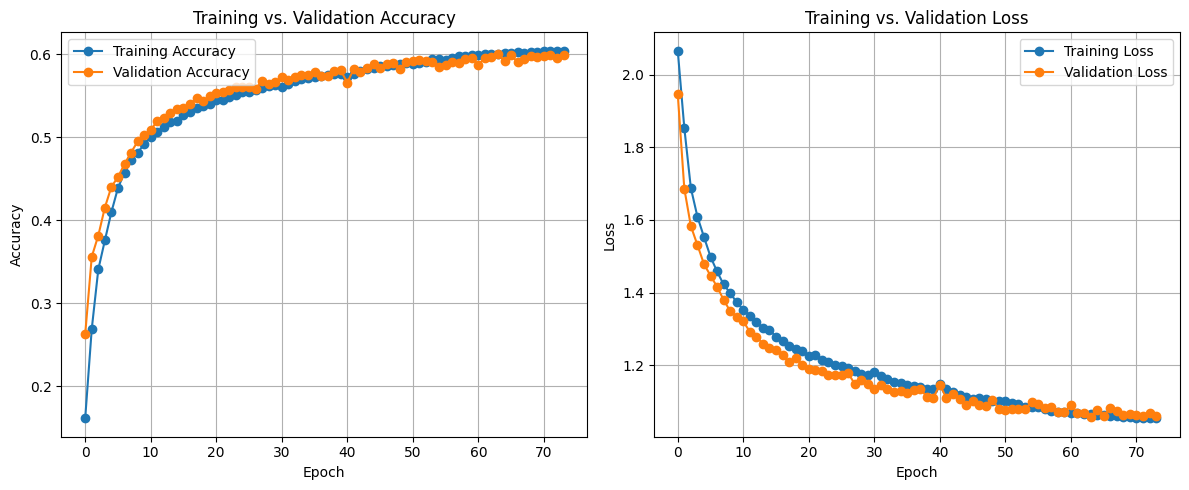

In [120]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', marker='o')
plt.title('Training vs. Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='o')
plt.title('Training vs. Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

**Evaluation**

In [121]:
# Predict on test set
y_pred = model.predict(X_test)
y_pred_labels = np.argmax(y_pred, axis=-1)

# Flatten for evaluation
y_true_flat = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

print("Accuracy:", accuracy_score(y_true_flat, y_pred_flat))
print(classification_report(y_true_flat, y_pred_flat))


7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 439ms/step
Accuracy: 0.5999182876275511
              precision    recall  f1-score   support

           0       0.47      0.35      0.40     25184
           1       0.45      0.56      0.50     24832
           2       0.40      0.45      0.42     25194
           3       0.46      0.32      0.38     25284
           4       0.62      0.72      0.67     25064
           5       0.63      0.67      0.65     24950
           6       0.89      0.83      0.86     25028
           7       0.88      0.90      0.89     25168

    accuracy                           0.60    200704
   macro avg       0.60      0.60      0.60    200704
weighted avg       0.60      0.60      0.60    200704



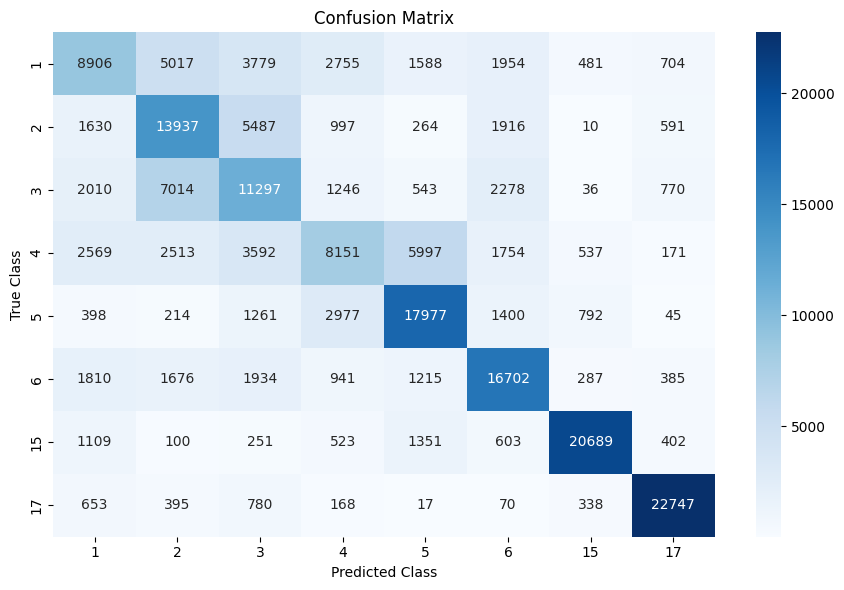

In [122]:
# Flatten labels
y_true = y_test.flatten()
y_pred_flat = y_pred_labels.flatten()

# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

##### test on unseen datafile

In [123]:
# === Einstellungen: Ordner, Block-Größe ===
TEST_FOLDER = "C:/Users/flori/Desktop/pa-1_data/clipped_files/Uster"
N_POINTS = 1024

# scaler, label_map und model müssen aus deinem Training im Workspace verfügbar sein
# scaler: dein StandardScaler
# label_map: dict original_class -> target_index
# model: dein trainiertes Keras-PointNet

# Listen zum Sammeln aller Blöcke und Labels
all_blocks = []
all_labels = []

# 1) Alle Dateien einlesen und Blocks extrahieren
file_paths = glob.glob(os.path.join(TEST_FOLDER, "*.laz"))
print(f"Gefundene Test-Dateien: {len(file_paths)}")

for path in file_paths:
    las = laspy.read(path)
    print(f"  -> verarbeite {os.path.basename(path)}")

    # Feature-Extraktion
    ground_h = np.min(las.z)
    feats = np.vstack((
        las.x,
        las.y,
        las.z,
        las.intensity,
        las.return_number,
        las.number_of_returns,
        las.z - ground_h,
        las.scan_angle
    )).T.astype(np.float32)

    # Label mapping und Filter
    y_raw = np.array(las.classification)
    y_mapped = np.array([label_map.get(c, -1) for c in y_raw], dtype=np.int32)
    mask = (y_mapped != -1)
    feats = feats[mask]
    y_mapped = y_mapped[mask]

    # Skalieren
    X_scaled = scaler.transform(feats)

    # In Blöcke à 1024 Punkte splitten
    n_blocks = len(X_scaled) // N_POINTS
    if n_blocks == 0:
        continue

    X_trim = X_scaled[: n_blocks * N_POINTS]
    y_trim = y_mapped[: n_blocks * N_POINTS]

    X_blocks = X_trim.reshape(n_blocks, N_POINTS, -1)
    y_blocks = y_trim.reshape(n_blocks, N_POINTS)

    # Zentrieren
    centroids = X_blocks[:, :, :3].mean(axis=1, keepdims=True)
    X_blocks[:, :, :3] -= centroids

    # Sammlung
    all_blocks.append(X_blocks)
    all_labels.append(y_blocks)

# 2) Alles zu einem großen Array zusammenführen
X_test = np.concatenate(all_blocks, axis=0)    # (total_blocks, 1024, features)
y_test = np.concatenate(all_labels, axis=0)    # (total_blocks, 1024)

print(f"\nGesamtzahl Test-Blöcke: {X_test.shape[0]}")

Gefundene Test-Dateien: 13
  -> verarbeite 2695500_1245000_cropped.laz
  -> verarbeite 2695500_1245500_cropped.laz
  -> verarbeite 2696000_1244000_cropped.laz
  -> verarbeite 2696000_1244500_cropped.laz
  -> verarbeite 2696000_1245000_cropped.laz
  -> verarbeite 2696000_1245500_cropped.laz
  -> verarbeite 2696000_1246000_cropped.laz
  -> verarbeite 2696500_1244000_cropped.laz
  -> verarbeite 2696500_1244500_cropped.laz
  -> verarbeite 2696500_1245000_cropped.laz
  -> verarbeite 2696500_1245500_cropped.laz
  -> verarbeite 2697000_1244500_cropped.laz
  -> verarbeite 2697000_1245000_cropped.laz

Gesamtzahl Test-Blöcke: 34334


In [124]:
# 3) Vorhersage über den gesamten Test-Datensatz
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=-1)

# 4) Flach auswerten
y_true_flat = y_test.flatten()
y_pred_flat = y_pred.flatten()

print("\n=== Gesamtauswertung über alle Dateien ===")
print(f"Accuracy: {accuracy_score(y_true_flat, y_pred_flat):.4f}\n")
print("Classification Report:")
print(classification_report(y_true_flat, y_pred_flat, digits=4))


=== Gesamtauswertung über alle Dateien ===
Accuracy: 0.2231

Classification Report:
              precision    recall  f1-score   support

           0     0.0249    0.6190    0.0479    733823
           1     0.7411    0.1117    0.1942  19574131
           2     0.0411    0.1742    0.0665    507208
           3     0.1822    0.1895    0.1858   1179522
           4     0.4996    0.7358    0.5951   3102739
           5     0.4333    0.2616    0.3263   9972083
           6     0.0000    0.0000    0.0000     11438
           7     0.0001    0.0000    0.0000     77072

    accuracy                         0.2231  35158016
   macro avg     0.2403    0.2615    0.1770  35158016
weighted avg     0.5868    0.2231    0.2614  35158016



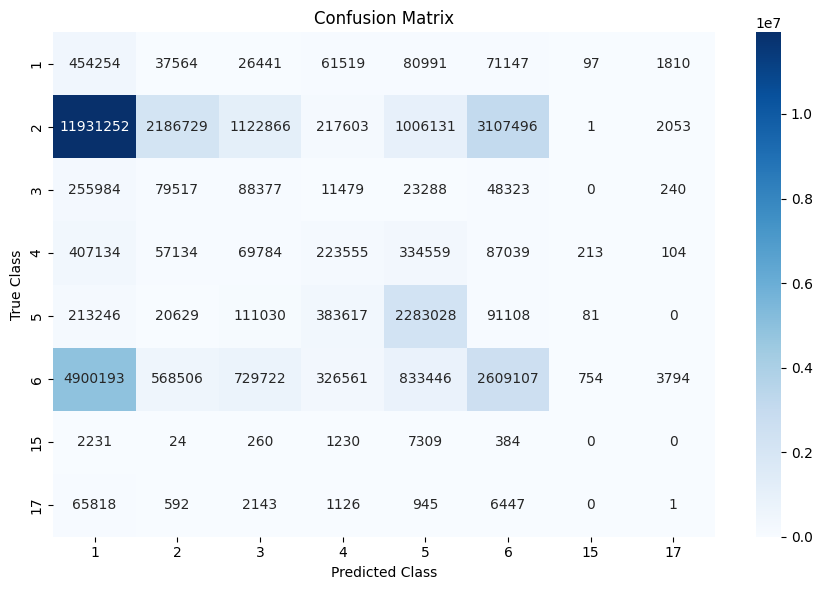

In [125]:
# Get inverse label map for display
inv_label_map = {v: k for k, v in label_map.items()}
labels = sorted(inv_label_map.keys())

# Compute confusion matrix
cm = confusion_matrix(y_true_flat, y_pred_flat, labels=labels)

# Plot
plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"{inv_label_map[i]}" for i in labels],
            yticklabels=[f"{inv_label_map[i]}" for i in labels])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.show()

### Basic PointNet++ Model

In [22]:
# === Imports and Model Definition ===

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import laspy
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset


class PointNetSetAbstraction(nn.Module):
    def __init__(self, in_channels, mlp_layers):
        super(PointNetSetAbstraction, self).__init__()
        layers = []
        last_channel = in_channels
        for out_channel in mlp_layers:
            layers.append(nn.Conv1d(last_channel, out_channel, kernel_size=1))
            layers.append(nn.BatchNorm1d(out_channel))
            layers.append(nn.ReLU())
            last_channel = out_channel
        self.mlp = nn.Sequential(*layers)

    def forward(self, x):
        return self.mlp(x)

class PointNetPlusPlus(nn.Module):
    def __init__(self, num_classes):
        super(PointNetPlusPlus, self).__init__()
        self.sa1 = PointNetSetAbstraction(6, [64, 128, 256])
        self.sa2 = PointNetSetAbstraction(256, [256, 512, 1024])
        self.fc1 = nn.Linear(1024, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, num_classes)
        self.dropout = nn.Dropout(p=0.3)
        
    def forward(self, x):
        x = self.sa1(x)
        x = self.sa2(x)
        x = torch.max(x, 2)[0]  # Global max pooling
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.dropout(x)
        x = self.fc3(x)
        return x




In [23]:
# === Load and Preprocess LAS File ===

las = laspy.read(path_flo)

ground_height = np.min(las.z)

X = np.vstack((
    las.x, 
    las.y, 
    las.z, 
    las.intensity, 
    las.return_number,  
    las.z - ground_height  
)).T.astype(np.float32)  

unique_labels = np.unique(las.classification)
label_map = {label: idx for idx, label in enumerate(unique_labels)}
y = np.array([label_map[label] for label in las.classification]).astype(np.int64)

sample_indices = np.random.choice(X.shape[0], size=50000, replace=False)
X = X[sample_indices]
y = y[sample_indices]

scaler = StandardScaler()
X = scaler.fit_transform(X)

# Convert to PyTorch tensors
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train = torch.tensor(X_train, dtype=torch.float32)  # Keep original shape
X_test = torch.tensor(X_test, dtype=torch.float32)  
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16)

NameError: name 'path_flo' is not defined

In [ ]:
# === Train PointNet++ Model ===

from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = PointNetPlusPlus(num_classes=len(unique_labels)).to(device)
X_train, X_test, y_train, y_test = X_train.to(device), X_test.to(device), y_train.to(device), y_test.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

num_epochs = 30

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        X_batch, y_batch = batch
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Reshape input to (batch_size, num_features, num_points)
        X_batch = X_batch.unsqueeze(2)  # Add a dummy dimension for num_points

        optimizer.zero_grad()
        outputs = model(X_batch)  # Now correctly shaped
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {total_loss:.4f}")

    # Reduce Learning Rate after 20 epochs
    if epoch == 15:
        for param_group in optimizer.param_groups:
            param_group['lr'] = 0.0001

Epoch 1/30:   0%|          | 0/2500 [00:00<?, ?it/s]

Epoch 1/30: 100%|██████████| 2500/2500 [02:41<00:00, 15.43it/s]


Epoch [1/30], Loss: 1980.4978


Epoch 2/30: 100%|██████████| 2500/2500 [02:47<00:00, 14.96it/s]


Epoch [2/30], Loss: 1788.0371


...

Epoch [28/30], Loss: 1349.8530


Epoch 29/30: 100%|██████████| 2500/2500 [02:54<00:00, 14.34it/s]


Epoch [29/30], Loss: 1353.4645


Epoch 30/30: 100%|██████████| 2500/2500 [02:47<00:00, 14.89it/s]

Epoch [30/30], Loss: 1363.0135


In [ ]:
# === Evaluate PointNet++ Model ===

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for batch in test_loader:
        X_batch, y_batch = batch
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        # Ensure correct shape (batch_size, num_features, num_points)
        X_batch = X_batch.unsqueeze(2)  # Add a dummy dimension for num_points
        
        outputs = model(X_batch)  # Pass correctly shaped input
        predicted = torch.argmax(outputs, dim=1)
        correct += (predicted == y_batch).sum().item()
        total += y_batch.size(0)

print(f"Test Accuracy: {correct / total:.4f}")


Test Accuracy: 0.7559


#### Evaluation
Model is more accurate than the very first PyTorch model but is much too slow for our amount of datapoints
Maybe with HPC this could be a promising option